# Tugas Lanjutan Pertemuan 11 — Mini Project Text Generation Bahasa Indonesia

**Dataset:** Indonesian-nlp/wikipedia-id (HuggingFace)

**Model 1:** LSTM Language Model    
**Model 2:** GRU Language Model     

**Alur notebook**
1. Setup & konfigurasi (dipakai bersama **jangan diubah salah satu saja**, agar perbandingan adil)
2. Load dataset & preprocessing (dipakai bersama)
3. Fungsi bantu: training, evaluasi, generate teks (dipakai bersama)
4. **Model 1 LSTM**
5. **Model 2 GRU**
6. Perbandingan kedua model (train/val loss, perplexity, next-word accuracy, waktu training, kualitas teks, repetisi, temperature)
7. Analisis, contoh output

Aktifkan GPU: `Runtime > Change runtime type > T4 GPU`.

## 1. Setup & Konfigurasi

In [ ]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

from IPython.display import display

# Seed eksperimen
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Hyperparameter sesuai modul praktikum
EMB_DIM = 64
RNN_UNITS = 96
EPOCHS = 8
BATCH_SIZE = 64
PATIENCE = 2

DATASET_PATH = "dataset_text_generation_indonesia.csv"

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
NumPy version: 2.4.6
GPU tersedia: []


In [ ]:

# Memuat dataset Hugging Face sesuai sumber data yang digunakan
from datasets import load_dataset
ds = load_dataset("indonesian-nlp/wikipedia-id")

print(ds)
print("Kolom dataset:", ds["train"].column_names)
print("Jumlah data train:", len(ds["train"]))
print("Jumlah data test :", len(ds["test"]))

# Mengambil sampel acak dari split train agar eksperimen dapat direproduksi.

SAMPLE_SIZE = 2500
SAMPLE_POOL_SIZE = min(15000, len(ds["train"]))

sample_pool = ds["train"].shuffle(seed=SEED).select(range(SAMPLE_POOL_SIZE))
df = sample_pool.to_pandas()

# Pastikan kolom yang diperlukan tersedia
required_columns = {"docid", "title", "text"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Kolom dataset tidak ditemukan: {missing_columns}")

# Bersihkan nilai text kosong, spasi berlebih di tepi, dan duplikasi artikel.
# Tidak melakukan normalisasi agresif agar isi teks sumber tetap terjaga.
df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"] != ""].copy()
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Hindari artikel yang terlalu pendek untuk tugas next-word prediction.
df["word_count_original"] = df["text"].str.split().str.len()
df = df[df["word_count_original"] >= 20].copy()

df = df[~df["text"].str.match(r"^\(\d+\)")].copy()                 # buang artikel asteroid bot
df = df[~df["text"].str.contains("asteroid", case=False)].copy()

if len(df) < SAMPLE_SIZE:
    raise ValueError(
        f"Setelah pemeriksaan data hanya tersedia {len(df)} artikel valid. "
        "Naikkan SAMPLE_POOL_SIZE agar memperoleh minimal 700 artikel."
    )

# Tetapkan tepat 700 artikel untuk eksperimen ini.
df = df.head(SAMPLE_SIZE).reset_index(drop=True)

print("Jumlah artikel terpilih:", len(df))
print("Kolom:", df.columns.tolist())
display(df[["docid", "title", "text", "word_count_original"]].head())

assert len(df) == SAMPLE_SIZE
assert df["text"].notna().all()
assert (df["text"].str.strip() != "").all()


DatasetDict({
    train: Dataset({
        features: ['docid', 'title', 'text'],
        num_rows: 1301683
    })
    test: Dataset({
        features: ['docid', 'title', 'text'],
        num_rows: 144632
    })
})
Kolom dataset: ['docid', 'title', 'text']
Jumlah data train: 1301683
Jumlah data test : 144632
Jumlah artikel terpilih: 2500
Kolom: ['docid', 'title', 'text', 'word_count_original']


,docid,title,text,word_count_original
0,846457#2,V-22 Osprey,Dua buah mesin Rolls-Royce AE 1107C pada kedua...,71
1,226157#22,Rinto Harahap,Popularitas Rinto bersama Lolypop mulai terlib...,132
2,524559#69,Pertanian dan perkebunan di Indonesia,"Selain itu, kelapa banyak terdapat di Aceh, Be...",29
3,641537#2,Dinasti ketujuh belas Mesir,Dua penguasa terakhir dinasti ketujuh belas me...,35
4,381771#0,Trbovlje,Trbovlje merupakan sebuah kotamadya berpendudu...,43


## Pembagian Data (80% train / 10% validation / 10% test)

In [ ]:
n = len(df)
a = int(0.8 * n)
b = int(0.9 * n)

train_texts = df.iloc[:a]["text"].tolist()
val_texts = df.iloc[a:b]["text"].tolist()
test_texts = df.iloc[b:]["text"].tolist()

print("Training   :", len(train_texts))
print("Validation :", len(val_texts))
print("Testing    :", len(test_texts))

assert len(train_texts) > 0 and len(val_texts) > 0 and len(test_texts) > 0

Training   : 2000
Validation : 250
Testing    : 250


##Tokenisasi dan Pembentukan Sequence

In [ ]:

MAX_TOKENS_PER_TEXT = 50
NUM_WORDS = 5000

# potong dulu baru fit, supaya kosakata hanya berisi kata yang benar-benar dilatih
train_texts_cut = [" ".join(t.split()[:MAX_TOKENS_PER_TEXT]) for t in train_texts]

tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts_cut)

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)
index_word = tokenizer.index_word

print("Vocabulary size:", vocab_size)

def make_seq(texts):
    sequences = []

    for text in texts:
        token_ids = tokenizer.texts_to_sequences([text])[0]

        # Batasi panjang artikel secara konsisten untuk mengendalikan memori.
        token_ids = token_ids[:MAX_TOKENS_PER_TEXT]

        for i in range(1, len(token_ids)):
            sequences.append(token_ids[:i + 1])

    return sequences

train_sequences = make_seq(train_texts)
val_sequences = make_seq(val_texts)
test_sequences = make_seq(test_texts)

print("Batas token per artikel:", MAX_TOKENS_PER_TEXT)
print("Jumlah sequence training   :", len(train_sequences))
print("Jumlah sequence validation :", len(val_sequences))
print("Jumlah sequence testing    :", len(test_sequences))


Vocabulary size: 5000
Batas token per artikel: 50
Jumlah sequence training   : 80663
Jumlah sequence validation : 10017
Jumlah sequence testing    : 9930


##Padding dan Pemisahan X–y

In [ ]:
if len(train_sequences) == 0:
    raise ValueError("Tidak terbentuk sequence training. Periksa isi dataset.")

max_len = max(len(seq) for seq in train_sequences)
if max_len < 2:
    raise ValueError("Sequence training terlalu pendek untuk next-word prediction.")

def prepare_xy(sequences):
    padded = pad_sequences(
        sequences,
        maxlen=max_len,
        padding="pre",
        truncating="pre"
    )
    X = padded[:, :-1]
    y = padded[:, -1]
    return X, y

X_train, y_train = prepare_xy(train_sequences)
X_val, y_val = prepare_xy(val_sequences)
X_test, y_test = prepare_xy(test_sequences)

print("Max sequence length:", max_len)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "| y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Max sequence length: 50
X_train: (80663, 49) | y_train: (80663,)
X_val  : (10017, 49) | y_val  : (10017,)
X_test : (9930, 49) | y_test : (9930,)


##Membangun Model LSTM dan GRU

In [ ]:
def build_lstm_model():
    inputs = layers.Input(shape=(max_len - 1,))

    x = layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMB_DIM
    )(inputs)

    x = layers.LSTM(RNN_UNITS)(x)

    outputs = layers.Dense(
        vocab_size,
        activation="softmax"
    )(x)

    model = models.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

lstm_model = build_lstm_model()
lstm_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 49)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 49, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 96)             │        61,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5000)           │       485,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 866,824 (3.31 MB)

 Trainable params: 866,824 (3.31 MB)

 Non-trainable params: 0 (0.00 B)

##Training dengan Early Stopping

Training Model LSTM dengan Early Stopping

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=PATIENCE,
    restore_best_weights=True
)

start_time = time.time()

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

time_lstm = time.time() - start_time

print(f"Waktu training LSTM: {time_lstm:.2f} detik")
print(f"Jumlah epoch yang dijalankan: {len(history_lstm.history['loss'])}")
print(f"Epoch dengan validation loss terendah: {np.argmin(history_lstm.history['val_loss']) + 1}")

Epoch 1/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 142s 111ms/step - accuracy: 0.1574 - loss: 6.4878 - val_accuracy: 0.2183 - val_loss: 5.7585
Epoch 2/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 135s 107ms/step - accuracy: 0.1797 - loss: 6.0521 - val_accuracy: 0.2558 - val_loss: 5.4767
Epoch 3/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 142s 113ms/step - accuracy: 0.2064 - loss: 5.7743 - val_accuracy: 0.2636 - val_loss: 5.3558
Epoch 4/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 136s 108ms/step - accuracy: 0.2180 - loss: 5.5701 - val_accuracy: 0.2667 - val_loss: 5.2731
Epoch 5/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 137s 104ms/step - accuracy: 0.2279 - loss: 5.3826 - val_accuracy: 0.2716 - val_loss: 5.2105
Epoch 6/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 133s 106ms/step - accuracy: 0.2343 - loss: 5.2028 - val_accuracy: 0.2685 - val_loss: 5.2005
Epoch 7/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 137s 108ms/step - accuracy: 0.2403 - loss: 5.0325 - val_accuracy: 0.2777 - val_loss: 5.1709
Epoch 8/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 132s 105ms/step - accuracy: 

### Kurva Training Loss vs Validation Loss

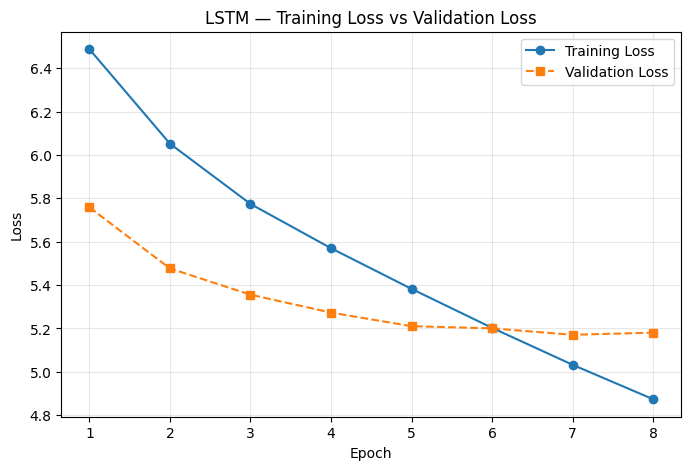

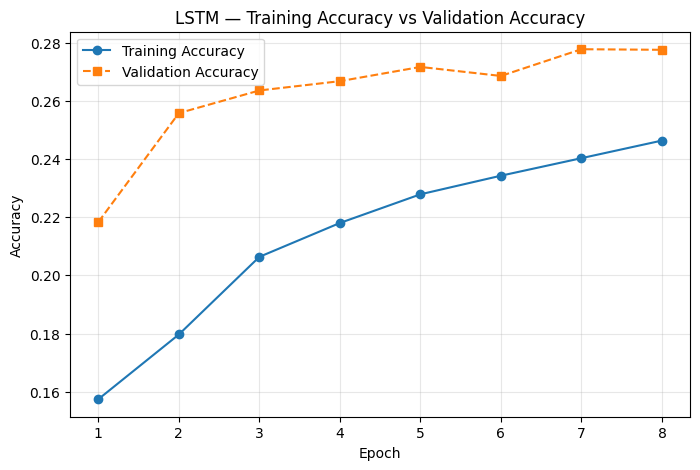

In [ ]:
epochs_range = range(1, len(history_lstm.history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history_lstm.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history_lstm.history["val_loss"], marker="s", linestyle="--", label="Validation Loss")
plt.title("LSTM — Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs_range))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history_lstm.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history_lstm.history["val_accuracy"], marker="s", linestyle="--", label="Validation Accuracy")
plt.title("LSTM — Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

##Evaluasi Model (Loss, Perplexity, Accuracy, Waktu Training)

In [ ]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

test_perplexity = float(np.exp(test_loss))

lstm_metrics = pd.DataFrame({
    "Model": ["LSTM"],
    "Test Loss": [test_loss],
    "Perplexity": [test_perplexity],
    "Next-word Accuracy": [test_accuracy],
    "Training Time (s)": [time_lstm]
})

display(lstm_metrics.round(4))

,Model,Test Loss,Perplexity,Next-word Accuracy,Training Time (s)
0,LSTM,5.0579,157.2526,0.2922,1094.1124


##Menghasilkan Teks (Temperature Sampling)

In [ ]:
def generate_text(model, seed_text, n_words=20, temperature=0.8):
    if temperature <= 0:
        raise ValueError("Temperature harus lebih besar dari 0.")

    generated_text = seed_text.strip()

    for _ in range(n_words):
        token_ids = tokenizer.texts_to_sequences([generated_text])[0]

        padded = pad_sequences(
            [token_ids],
            maxlen=max_len - 1,
            padding="pre",
            truncating="pre"
        )

        probabilities = model.predict(padded, verbose=0)[0].astype("float64")

        # ID 0 adalah padding, sehingga tidak boleh dipilih sebagai kata berikutnya.
        probabilities[1] = 0.0

        # Temperature sampling dalam ruang log agar lebih stabil secara numerik.
        logits = np.log(np.maximum(probabilities, 1e-12)) / temperature
        logits -= np.max(logits)

        probabilities = np.exp(logits)
        probabilities /= probabilities.sum()

        next_id = np.random.choice(len(probabilities), p=probabilities)
        next_word = index_word.get(next_id, "<OOV>")

        generated_text += " " + next_word

    return generated_text

np.random.seed(SEED)
example_output = generate_text(
    lstm_model,
    seed_text="mahasiswa mengembangkan",
    n_words=20,
    temperature=0.8
)

print("Prompt : mahasiswa mengembangkan")
print("Output :", example_output)

Prompt : mahasiswa mengembangkan
Output : mahasiswa mengembangkan salah satu bintang satu dalam desa yang berpori dan kebanyakan tahun panci oleh the dengan berbagai periode bulan november 2011


###pengujian pengaruh temperature


In [ ]:
TEMPERATURES = [0.5, 0.8, 1.0, 1.2]
TEMPERATURE_PROMPT = "tim laboratorium"

temperature_outputs = []

for temp in TEMPERATURES:
    np.random.seed(SEED)
    output = generate_text(
        lstm_model,
        seed_text=TEMPERATURE_PROMPT,
        n_words=18,
        temperature=temp
    )

    temperature_outputs.append({
        "Model": "LSTM",
        "Prompt": TEMPERATURE_PROMPT,
        "Temperature": temp,
        "Generated Text": output
    })

    print(f"\nTemperature {temp}")
    print(output)

temperature_df = pd.DataFrame(temperature_outputs)


Temperature 0.5
tim laboratorium panjang ke klub di antara desa yang ditemukan pada tahun 3 1970 ia ia menjadi orang di mana

Temperature 0.8
tim laboratorium sepak 2000 ketika disutradarai pada tahun sekitar putaran sebesar 2012 yang mendekati senang dengan salah satu kota ini

Temperature 1.0
tim laboratorium kapal potensial melewati susu para pemain di didukung oleh kopi yang ditentukan ditambahkan pada tahun 2006 untuk menarik

Temperature 1.2
tim laboratorium daftar cerdas diangkat sejak dalam tiga dalam diameter melahirkan utamanya dan mesinnya disini dengan 7 hari jawa utama


repetisi output lstm


In [ ]:
def repetition_rate(generated_only_text):
    words = generated_only_text.lower().split()
    bigrams = list(zip(words[:-1], words[1:]))

    if len(bigrams) == 0:
        return 0.0

    return 1.0 - (len(set(bigrams)) / len(bigrams))


def generate_only(model, seed_text, n_words=30, temperature=0.8):
    full_text = generate_text(
        model,
        seed_text=seed_text,
        n_words=n_words,
        temperature=temperature
    )

    # Menghapus prompt dari awal output untuk mengukur repetisi hasil generasi saja.
    prefix = seed_text.strip()
    if full_text.startswith(prefix):
        return full_text[len(prefix):].strip()

    return full_text


repetition_rows = []

for temp in TEMPERATURES:
    rates = []

    for run_seed in range(5):
        np.random.seed(run_seed)
        generated = generate_only(
            lstm_model,
            seed_text="mahasiswa mengembangkan",
            n_words=30,
            temperature=temp
        )
        rates.append(repetition_rate(generated))

    repetition_rows.append({
        "Model": "LSTM",
        "Temperature": temp,
        "Rata-rata Repetition Rate (5 run)": float(np.mean(rates))
    })

repetition_df = pd.DataFrame(repetition_rows)
display(repetition_df.round(4))

,Model,Temperature,Rata-rata Repetition Rate (5 run)
0,LSTM,0.5,0.0414
1,LSTM,0.8,0.0069
2,LSTM,1.0,0.0000
3,LSTM,1.2,0.0000


Ringkasan hasil LSTM dan pemeriksaan kelengkapan

In [ ]:
history_df = pd.DataFrame({
    "Epoch": range(1, len(history_lstm.history["loss"]) + 1),
    "Training Loss": history_lstm.history["loss"],
    "Validation Loss": history_lstm.history["val_loss"],
    "Training Accuracy": history_lstm.history["accuracy"],
    "Validation Accuracy": history_lstm.history["val_accuracy"]
})

print("METRIK TEST LSTM")
display(lstm_metrics.round(4))

print("RIWAYAT TRAINING")
display(history_df.round(4))

print("PENGUJIAN TEMPERATURE")
display(temperature_df)

print("REPETITION RATE")
display(repetition_df.round(4))



METRIK TEST LSTM


,Model,Test Loss,Perplexity,Next-word Accuracy,Training Time (s)
0,LSTM,5.0579,157.2526,0.2922,1094.1124


RIWAYAT TRAINING


,Epoch,Training Loss,Validation Loss,Training Accuracy,Validation Accuracy
0,1,6.4878,5.7585,0.1574,0.2183
1,2,6.0521,5.4767,0.1797,0.2558
2,3,5.7743,5.3558,0.2064,0.2636
3,4,5.5701,5.2731,0.2180,0.2667
4,5,5.3826,5.2105,0.2279,0.2716
5,6,5.2028,5.2005,0.2343,0.2685
6,7,5.0325,5.1709,0.2403,0.2777
7,8,4.8737,5.1805,0.2463,0.2775


PENGUJIAN TEMPERATURE


,Model,Prompt,Temperature,Generated Text
0,LSTM,tim laboratorium,0.5,tim laboratorium panjang ke klub di antara des...
1,LSTM,tim laboratorium,0.8,tim laboratorium sepak 2000 ketika disutradara...
2,LSTM,tim laboratorium,1.0,tim laboratorium kapal potensial melewati susu...
3,LSTM,tim laboratorium,1.2,tim laboratorium daftar cerdas diangkat sejak ...


REPETITION RATE


,Model,Temperature,Rata-rata Repetition Rate (5 run)
0,LSTM,0.5,0.0414
1,LSTM,0.8,0.0069
2,LSTM,1.0,0.0000
3,LSTM,1.2,0.0000


Membangun Model GRU

In [ ]:
def build_gru_model():
    inputs = layers.Input(shape=(max_len - 1,))

    x = layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMB_DIM
    )(inputs)

    x = layers.GRU(RNN_UNITS)(x)

    outputs = layers.Dense(
        vocab_size,
        activation="softmax"
    )(x)

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

tf.keras.utils.set_random_seed(SEED)
gru_model = build_gru_model()
gru_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 49)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 49, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 96)             │        46,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5000)           │       485,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 851,656 (3.25 MB)

 Trainable params: 851,656 (3.25 MB)

 Non-trainable params: 0 (0.00 B)

Training Model GRU dengan Early Stopping


In [ ]:
early_stopping_gru = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=PATIENCE,
    restore_best_weights=True
)

start_time_gru = time.time()

history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_gru],
    verbose=1
)

time_gru = time.time() - start_time_gru
best_epoch_gru = int(np.argmin(history_gru.history["val_loss"]) + 1)

print(f"Waktu training GRU: {time_gru:.2f} detik")
print(f"Jumlah epoch yang dijalankan: {len(history_gru.history['loss'])}")
print(f"Epoch dengan validation loss terendah: {best_epoch_gru}")

Epoch 1/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 138s 107ms/step - accuracy: 0.1641 - loss: 6.4169 - val_accuracy: 0.2493 - val_loss: 5.5170
Epoch 2/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 138s 105ms/step - accuracy: 0.2085 - loss: 5.7758 - val_accuracy: 0.2657 - val_loss: 5.2585
Epoch 3/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 151s 120ms/step - accuracy: 0.2259 - loss: 5.4042 - val_accuracy: 0.2725 - val_loss: 5.1625
Epoch 4/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 140s 111ms/step - accuracy: 0.2399 - loss: 5.1098 - val_accuracy: 0.2752 - val_loss: 5.1340
Epoch 5/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 135s 106ms/step - accuracy: 0.2515 - loss: 4.8563 - val_accuracy: 0.2730 - val_loss: 5.1407
Epoch 6/8
1261/1261 ━━━━━━━━━━━━━━━━━━━━ 133s 106ms/step - accuracy: 0.2621 - loss: 4.6303 - val_accuracy: 0.2710 - val_loss: 5.1611
Waktu training GRU: 845.72 detik
Jumlah epoch yang dijalankan: 6
Epoch dengan validation loss terendah: 4


Kurva Training dan Validation Loss serta Accuracy

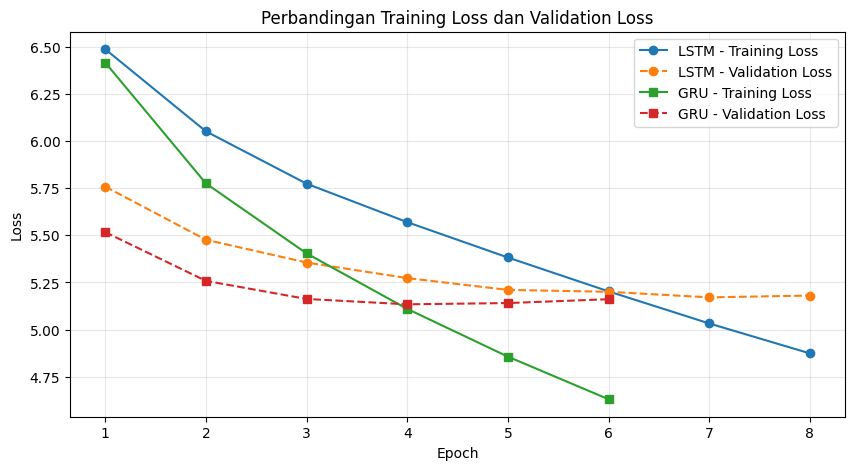

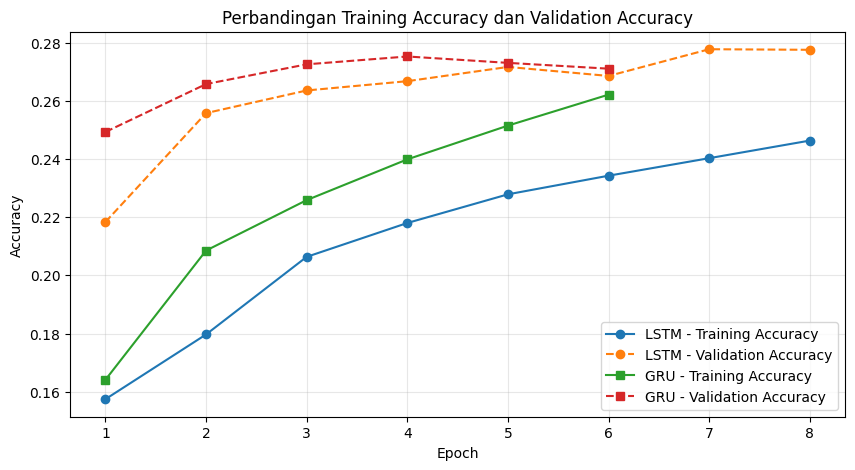

In [ ]:
# Plot loss LSTM dan GRU dalam grafik yang sama.
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history_lstm.history["loss"]) + 1),
         history_lstm.history["loss"], marker="o", label="LSTM - Training Loss")
plt.plot(range(1, len(history_lstm.history["val_loss"]) + 1),
         history_lstm.history["val_loss"], marker="o", linestyle="--", label="LSTM - Validation Loss")
plt.plot(range(1, len(history_gru.history["loss"]) + 1),
         history_gru.history["loss"], marker="s", label="GRU - Training Loss")
plt.plot(range(1, len(history_gru.history["val_loss"]) + 1),
         history_gru.history["val_loss"], marker="s", linestyle="--", label="GRU - Validation Loss")
plt.title("Perbandingan Training Loss dan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Plot akurasi LSTM dan GRU.
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history_lstm.history["accuracy"]) + 1),
         history_lstm.history["accuracy"], marker="o", label="LSTM - Training Accuracy")
plt.plot(range(1, len(history_lstm.history["val_accuracy"]) + 1),
         history_lstm.history["val_accuracy"], marker="o", linestyle="--", label="LSTM - Validation Accuracy")
plt.plot(range(1, len(history_gru.history["accuracy"]) + 1),
         history_gru.history["accuracy"], marker="s", label="GRU - Training Accuracy")
plt.plot(range(1, len(history_gru.history["val_accuracy"]) + 1),
         history_gru.history["val_accuracy"], marker="s", linestyle="--", label="GRU - Validation Accuracy")
plt.title("Perbandingan Training Accuracy dan Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Evaluasi GRU pada Data Test

In [ ]:
gru_test_loss, gru_test_accuracy = gru_model.evaluate(
    X_test, y_test, verbose=0
)
gru_test_perplexity = float(np.exp(gru_test_loss))

gru_metrics = pd.DataFrame({
    "Model": ["GRU"],
    "Test Loss": [gru_test_loss],
    "Perplexity": [gru_test_perplexity],
    "Next-word Accuracy": [gru_test_accuracy],
    "Training Time (s)": [time_gru]
})

display(gru_metrics.round(4))

,Model,Test Loss,Perplexity,Next-word Accuracy,Training Time (s)
0,GRU,4.9993,148.307,0.2972,845.7152


Contoh Text Generation dari GRU

In [ ]:
np.random.seed(SEED)
gru_example_output = generate_text(
    gru_model,
    seed_text="mahasiswa mengembangkan",
    n_words=20,
    temperature=0.8
)

print("Prompt : mahasiswa mengembangkan")
print("Output GRU:", gru_example_output)

Prompt : mahasiswa mengembangkan
Output GRU: mahasiswa mengembangkan karya normal pada tanggal 1 mei 2009 sang dokter berita dan namco ekstrem pada tahun 2011 dari posisi februari 2006


Perbandingan Metrik LSTM dan GRU

In [ ]:
# Gabungkan metrik test kedua model.
comparison_metrics = pd.concat(
    [lstm_metrics, gru_metrics],
    ignore_index=True
)

# Tambahkan informasi validation loss terbaik dan jumlah parameter.
comparison_metrics["Best Validation Loss"] = [
    float(min(history_lstm.history["val_loss"])),
    float(min(history_gru.history["val_loss"]))
]
comparison_metrics["Best Epoch"] = [
    int(np.argmin(history_lstm.history["val_loss"]) + 1),
    int(np.argmin(history_gru.history["val_loss"]) + 1)
]
comparison_metrics["Total Parameters"] = [
    lstm_model.count_params(),
    gru_model.count_params()
]

print("PERBANDINGAN MODEL LSTM DAN GRU")
display(comparison_metrics.round(4))

# Ringkasan otomatis berdasarkan angka eksperimen aktual.
print("\nRINGKASAN OTOMATIS")
lowest_ppl_model = comparison_metrics.loc[comparison_metrics["Perplexity"].idxmin(), "Model"]
highest_acc_model = comparison_metrics.loc[comparison_metrics["Next-word Accuracy"].idxmax(), "Model"]
fastest_model = comparison_metrics.loc[comparison_metrics["Training Time (s)"].idxmin(), "Model"]
lowest_val_model = comparison_metrics.loc[comparison_metrics["Best Validation Loss"].idxmin(), "Model"]
print(f"Perplexity lebih rendah : {lowest_ppl_model}")
print(f"Next-word accuracy tertinggi : {highest_acc_model}")
print(f"Waktu training tercepat : {fastest_model}")
print(f"Best validation loss terendah : {lowest_val_model}")
print("Catatan: ringkasan angka tidak menggantikan penilaian kualitas teks secara manual.")

PERBANDINGAN MODEL LSTM DAN GRU


,Model,Test Loss,Perplexity,Next-word Accuracy,Training Time (s),Best Validation Loss,Best Epoch,Total Parameters
0,LSTM,5.0579,157.2526,0.2922,1094.1124,5.1709,7,866824
1,GRU,4.9993,148.3070,0.2972,845.7152,5.1340,4,851656



RINGKASAN OTOMATIS
Perplexity lebih rendah : GRU
Next-word accuracy tertinggi : GRU
Waktu training tercepat : GRU
Best validation loss terendah : GRU
Catatan: ringkasan angka tidak menggantikan penilaian kualitas teks secara manual.


Pengaruh Temperature pada LSTM dan GRU

In [ ]:
TEMPERATURES = [0.5, 0.8, 1.0, 1.2]
TEMPERATURE_PROMPT = "tim laboratorium"

temperature_comparison_rows = []

for model_name, model in [("LSTM", lstm_model), ("GRU", gru_model)]:
    for temp in TEMPERATURES:
        np.random.seed(SEED)
        output = generate_text(
            model,
            seed_text=TEMPERATURE_PROMPT,
            n_words=18,
            temperature=temp
        )
        temperature_comparison_rows.append({
            "Model": model_name,
            "Prompt": TEMPERATURE_PROMPT,
            "Temperature": temp,
            "Generated Text": output
        })

temperature_comparison_df = pd.DataFrame(temperature_comparison_rows)
display(temperature_comparison_df)

,Model,Prompt,Temperature,Generated Text
0,LSTM,tim laboratorium,0.5,tim laboratorium panjang ke klub di antara des...
1,LSTM,tim laboratorium,0.8,tim laboratorium sepak 2000 ketika disutradara...
2,LSTM,tim laboratorium,1.0,tim laboratorium kapal potensial melewati susu...
3,LSTM,tim laboratorium,1.2,tim laboratorium daftar cerdas diangkat sejak ...
4,GRU,tim laboratorium,0.5,tim laboratorium salah satu karya yang memilik...
5,GRU,tim laboratorium,0.8,tim laboratorium 12 1987 untuk membangun wilay...
6,GRU,tim laboratorium,1.0,tim laboratorium ialah fredi kumbang tanduk pa...
7,GRU,tim laboratorium,1.2,tim laboratorium sifat mauro kaya membeli bara...


**Perbandingan Tingkat Repetisi**

Repetition rate dihitung dari pengulangan bigram pada teks hasil generasi (prompt tidak ikut dihitung). Nilai yang lebih kecil menunjukkan lebih sedikit bigram berulang menurut definisi metrik ini.

In [ ]:
repetition_comparison_rows = []

for model_name, model in [("LSTM", lstm_model), ("GRU", gru_model)]:
    for temp in TEMPERATURES:
        rates = []
        for run_seed in range(5):
            np.random.seed(run_seed)
            generated_only_text = generate_only(
                model,
                seed_text="mahasiswa mengembangkan",
                n_words=30,
                temperature=temp
            )
            rates.append(repetition_rate(generated_only_text))

        repetition_comparison_rows.append({
            "Model": model_name,
            "Temperature": temp,
            "Rata-rata Repetition Rate (5 run)": float(np.mean(rates)),
            "Std Repetition Rate": float(np.std(rates))
        })

repetition_comparison_df = pd.DataFrame(repetition_comparison_rows)
display(repetition_comparison_df.round(4))

,Model,Temperature,Rata-rata Repetition Rate (5 run),Std Repetition Rate
0,LSTM,0.5,0.0414,0.0338
1,LSTM,0.8,0.0069,0.0138
2,LSTM,1.0,0.0000,0.0000
3,LSTM,1.2,0.0000,0.0000
4,GRU,0.5,0.0414,0.0338
5,GRU,0.8,0.0000,0.0000
6,GRU,1.0,0.0000,0.0000
7,GRU,1.2,0.0000,0.0000


# **KESIMPULAN**

Pada *eksperimen* ini, GRU sedikit lebih baik daripada LSTM di semua metrik angka. GRU memperoleh perplexity 148,31 (LSTM 157,25), test loss 4,9993 (LSTM 5,0579), next-word accuracy 29,72% (LSTM 29,22%), dan validation loss terbaik 5,1340 (LSTM 5,1709). GRU juga lebih cepat dilatih (845,72 detik vs 1094,11 detik). Tetapi selisih waktu ini terutama karena early stopping menghentikan GRU di epoch 6, sedangkan LSTM berjalan 8 epoch. Waktu per epoch kedua model hampir sama (sekitar 141 detik untuk GRU dan 137 detik untuk LSTM). GRU juga mulai overfitting lebih awal: validation loss terendah ada di epoch 4, lalu *naik*, sementara training loss terus turun. Selisih antar model kecil dan berasal dari satu kali training, jadi belum cukup kuat untuk menyimpulkan bahwa GRU selalu lebih baik.

Perplexity yang lebih rendah tidak otomatis membuat teks lebih natural. Teks dari kedua model masih tidak koheren: kalimat melompat ke topik acak bergaya Wikipedia (tanggal, tahun, nama) dan tidak mengikuti prompt. Contohnya, “mahasiswa mengembangkan” dilanjutkan menjadi “...karya normal pada tanggal 1 mei 2009...” (GRU) dan “...salah satu bintang satu dalam desa...” (LSTM). Ini wajar karena model kecil, dilatih dari 2.000 artikel yang dipotong 50 kata, dengan akurasi next-word sekitar 30%. Repetisi bigram paling tinggi pada temperature 0,5 (0,0414 untuk kedua model), dan 0,0000 pada temperature 1,0 dan 1,2. Namun repetisi rendah tidak berarti teks bagus, karena kata-katanya makin acak. Karena itu, model sebaiknya dinilai dari angka dan penilaian manual kualitas teks secara bersamaan.